# Study 2 pilot: can development cause failure, and can mitigation avoid it?

- The current environment uses nonlinear emissions (`8 + 0.10 × EDI + 0.001 × EDI²`), prevention-only mitigation, high mitigation capacity 20, and the combined economic reward.
- Saved outputs in this notebook are historical. A rerun writes to `../results/pilot_current` so earlier files remain available.

In [1]:
import json
import random

import matplotlib.pyplot as plt
import pandas as pd

from study_2_economic_sustainability.config import EnvironmentConfig
from study_2_economic_sustainability.environment import EconomicSustainabilityEnvironment

## Settings

In [2]:
BASELINE_NAMES = ("save", "develop", "mitigate", "coordinate", "random_affordable")
PILOT_SEEDS = tuple(range(1000, 1020))
POLICIES = BASELINE_NAMES # save, develop, mitigate, coordinate, random affordable
RESULTS_DIRECTORY = "../results/pilot_current"
TRAJECTORY_SEED = PILOT_SEEDS[0]
environment_config = EnvironmentConfig()

## Baseline rules

These are the same five decisions explored one by one in notebook 00. Each rule chooses an action for all four regions.

### Save and develop

Save spends nothing. Develop buys action 1 when the region can afford it and its EDI is below 100.

In [3]:
def save_policy(environment, observations, rng):
    return (0, 0, 0, 0)


def develop_policy(environment, observations, rng):
    actions = []
    cost = environment.config.action_costs[1]

    for region in range(4):
        balance = environment.currency_balances[region]
        edi = environment.development_indices[region]
        if edi < 100 and balance >= cost:
            actions.append(1)
        else:
            actions.append(0)

    return tuple(actions)

### Mitigate

Choose the strongest mitigation action the region can currently afford.

In [4]:
def strongest_affordable_mitigation(balance, costs):
    for action in (4, 3, 2):
        if balance >= costs[action]:
            return action

    return 0


def mitigate_policy(environment, observations, rng):
    actions = []

    for balance in environment.currency_balances:
        action = strongest_affordable_mitigation(balance, environment.config.action_costs)
        actions.append(action)

    return tuple(actions)

### Coordinate

Mitigate when local pollution or the shared index moves above the lowest bin. Otherwise, develop up to EDI 70 when affordable.

In [5]:
def coordinate_policy(environment, observations, rng):
    actions = []
    costs = environment.config.action_costs

    for region in range(4):
        balance = environment.currency_balances[region]
        edi = environment.development_indices[region]
        local_bin = observations[region][2]
        global_bin = observations[region][3]

        if local_bin >= 1 or global_bin >= 1:
            action = strongest_affordable_mitigation(balance, costs)
        elif edi < 70 and balance >= costs[1]:
            action = 1
        else:
            action = 0

        actions.append(action)

    return tuple(actions)

### Random affordable

Draw from currently affordable actions. Development is excluded once EDI reaches 100.

In [6]:
def random_affordable_policy(environment, observations, rng):
    if rng is None:
        raise ValueError("Random affordable needs a seeded generator")

    actions = []
    costs = environment.config.action_costs

    for region in range(4):
        balance = environment.currency_balances[region]
        edi = environment.development_indices[region]
        affordable = []

        for action in range(5):
            if balance >= costs[action] and (action != 1 or edi < 100):
                affordable.append(action)

        actions.append(rng.choice(affordable))

    return tuple(actions)

In [7]:
BASELINE_POLICIES = {
    "save": save_policy,
    "develop": develop_policy,
    "mitigate": mitigate_policy,
    "coordinate": coordinate_policy,
    "random_affordable": random_affordable_policy,
}

## Run one pilot episode

The episode loop keeps the six measurements used below. It stores step-by-step GPI only for the one seed selected for the plot.

In [ ]:
def record_episode_step(totals, actions, info, environment, trajectory, keep_trajectory):
    totals["gpi"] += info["global_pollution_index"]
    totals["maximum_pollution"] = max(
        totals["maximum_pollution"], max(info["pollution_loads"])
    )

    for region in range(4):
        if actions[region] in (2, 3, 4):
            totals["mitigation_spending"] += info["costs_paid"][region]

    if keep_trajectory:
        trajectory.append({
            "step": environment.step_count,
            "gpi": info["global_pollution_index"],
        })


In [ ]:
def summarize_episode(environment, policy, seed, totals, terminated):
    return {
        "policy": policy,
        "environment_seed": seed,
        "steps": environment.step_count,
        "terminated": terminated,
        "mean_gpi": totals["gpi"] / environment.step_count,
        "mean_final_edi": sum(environment.development_indices) / 4,
        "mitigation_spending": totals["mitigation_spending"],
        "maximum_pollution": totals["maximum_pollution"],
    }


In [ ]:
def run_episode(environment, seed, policy, policy_rng=None, keep_trajectory=False):
    observations = environment.reset(seed)
    totals = {
        "gpi": 0.0,
        "mitigation_spending": 0.0,
        "maximum_pollution": max(environment.pollution_loads),
    }
    trajectory = []

    while True:
        actions = BASELINE_POLICIES[policy](environment, observations, policy_rng)
        observations, rewards, terminated, truncated, info = environment.step(actions)
        record_episode_step(totals, actions, info, environment, trajectory, keep_trajectory)

        if terminated or truncated:
            break

    result = summarize_episode(environment, policy, seed, totals, terminated)
    return result, trajectory


## Run pilot episodes

The policies are:
- Save every step
- Develop whenever possible
- Buy the strongest affordable mitigation
- Use a simple pollution-bin coordination rule
- Choose randomly among affordable actions.

In [9]:
episode_rows = []
trajectory_rows = []

In [10]:
for policy in POLICIES:
    for seed in PILOT_SEEDS:
        environment = EconomicSustainabilityEnvironment(config=environment_config)
        action_rng = random.Random(seed + 1_000_000)
        row, trajectory = run_episode(
            environment,
            seed,
            policy,
            policy_rng=action_rng,
            keep_trajectory=(seed == TRAJECTORY_SEED),
        )
        episode_rows.append(row)

        for point in trajectory:
            trajectory_rows.append({"policy": policy, "environment_seed": seed, **point})

In [11]:
episodes = pd.DataFrame(episode_rows)
trajectories = pd.DataFrame(trajectory_rows)
episodes.to_csv(f"{RESULTS_DIRECTORY}/episodes.csv", index=False)
trajectories.to_csv(f"{RESULTS_DIRECTORY}/trajectories.csv", index=False)

In [12]:
with open(f"{RESULTS_DIRECTORY}/settings.json", "w", encoding="utf-8") as file:
    json.dump({
        "environment": vars(environment_config),
        "environment_seeds": PILOT_SEEDS,
        "policies": POLICIES,
        "random_action_seed_rule": "environment seed + 1000000",
        "notebook": "study_2_economic_sustainability/notebooks/02_pilot_dynamics.ipynb",
    }, file, indent=2)
    file.write("\n")

print(f"Saved {len(episodes)} episodes and {len(trajectories)} trajectory points")

Saved 100 episodes and 823 trajectory points


## Compare outcome

In [13]:
summary = episodes.groupby("policy", sort=False).agg(
    failure_fraction=("terminated", "mean"),
    mean_steps=("steps", "mean"),
    mean_gpi=("mean_gpi", "mean"),
    mean_final_edi=("mean_final_edi", "mean"),
    mean_mitigation_spending=("mitigation_spending", "mean"),
    maximum_pollution_seen=("maximum_pollution", "max"),
)
display(summary.round(2))

,failure_fraction,mean_steps,mean_gpi,mean_final_edi,mean_mitigation_spending,maximum_pollution_seen
policy,,,,,,
save,0.0,200.0,55.08,0.00,0.0,56.00
develop,1.0,25.5,73.46,83.11,0.0,100.81
mitigate,0.0,200.0,1.37,0.00,18088.5,10.00
coordinate,0.0,200.0,28.44,70.00,14617.5,46.19
random_affordable,0.0,200.0,32.06,99.80,14881.5,88.30


Each row summarizes **20 episodes** for one rule. The six columns mean:

- `failure_fraction`: share of episodes that reached the pollution failure threshold. A value of 1.0 means all 20 failed.
- `mean_steps`: average episode length. The limit is 200 steps; an earlier ending indicates failure here.
- `mean_gpi`: average Global Pollution Index during each episode, then averaged across the 20 starts. Lower means less pollution.
- `mean_final_edi`: average final Economic Development Index across the four regions and 20 starts. Higher means more development.
- `mean_mitigation_spending`: total mitigation cost across regions and steps, averaged per episode.
- `maximum_pollution_seen`: the highest **regional** pollution load seen in any of the 20 episodes. This is a maximum, not an average.

Develop-only failed on every start after 25.5 steps on average, so its mean GPI of 73.46 covers much shorter episodes than the other rows. Mitigate reached the lowest mean GPI (1.37), but final EDI stayed at zero and spending was about 18,089 per episode. Coordinate reached EDI 70 with mean GPI 28.44. Save spent nothing and made no development. Random affordable nearly reached EDI 100 and avoided failure, but its maximum regional load reached 88.30, closer to the failure threshold of 100.

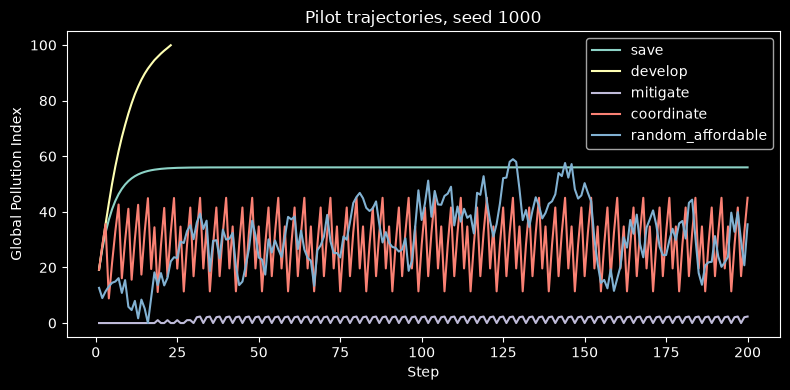

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
for policy in POLICIES:
    points = trajectories[trajectories["policy"] == policy]
    ax.plot(points["step"], points["gpi"], label=policy)
ax.set(xlabel="Step", ylabel="Global Pollution Index", title=f"Pilot trajectories, seed {TRAJECTORY_SEED}")
ax.legend()
fig.tight_layout()
fig.savefig(f"{RESULTS_DIRECTORY}/images/gpi_trajectories.svg")
plt.show()

- **Develop:** Pollution increases rapidly, reaching the failure threshold around step 23 and ending the episode early.
- **Save:** Pollution quickly rises to approximately 56 GPI and remains constant throughout the episode.
- **Mitigate:** Maintains pollution near zero, with small fluctuations.
- **Coordinate:** Pollution fluctuates regularly between approximately 10 and 45 GPI, without reaching the failure threshold.
- **Random-affordable:** Shows irregular pollution fluctuations, occasionally reaching nearly 60 GPI, but completes all 200 steps.

**Key takeaway:** Mitigation is highly effective at controlling pollution, while development without mitigation leads to rapid environmental failure. Coordination and random actions prevent failure in this episode but produce less stable pollution levels.

### What This Pilot Notebook Tells Us

- **Develop-only** caused environmental failure, confirming that uncontrolled development is unsustainable.
- **Mitigate-only** maintained very low pollution but prevented economic development and required substantial spending.
- **Coordination** allowed some development while keeping pollution lower than saving.
- The other four policies completed all 20 episodes without environmental failure.

**Key takeaway:** The environment creates a meaningful tradeoff between economic development and pollution control, making it suitable for comparing different reward structures.

These results evaluate fixed baseline policies, not learned agents. The graph shows only one of the 20 starting seeds.